# Modelo *stepping-stone* bidimensional

Código del segundo experimento de la tesis de Maestría en Ingeniería Matemática.

Se utiliza la primera réplica de los datos simulados por Díaz-Papkovich et al. (`2D_stepstone_1.vcf`): 9 demes sobre una retícula $3\times3$, 500 individuos por deme y 16.666 variantes. Las etiquetas y las posiciones de los demes no intervienen en las distancias de Fermat.

El notebook sigue las Secciones **4.3 y 5.2** y el **Anexo C.1** de la tesis:

1. Datos y diferenciación genética (Cuadro 5.2).
2. Aparición de atajos (Figura 5.2).
3. Representaciones y métricas (Figuras 5.3 y 5.4).
4. Caminos entre P1 y P8 (Figura 5.5 y Cuadro 5.3).
5. Robustez sobre 30 réplicas (Anexo C.1).

**Datos externos.** Se deben descargar los archivos VCF de las simulaciones de Díaz-Papkovich et al. desde [Zenodo](https://zenodo.org/records/17545804) y descomprimilos en `2D_stepstone/`. No se incluyen aquí los archivos originales. Se aceptan tanto `2D_stepstone/2D_stepstone_1.vcf` como `2D_stepstone/2D_stepstone_1.vcf/2D_stepstone_1.vcf` (igual para las demás réplicas).

**Ejecución.** Las matrices de distancias tienen tamaño $4500\times4500$. El cálculo de Floyd–Warshall, las descomposiciones espectrales y el análisis de las 30 réplicas pueden tardar varias horas y utilizar bastante memoria. Las tablas CSV y las figuras PNG/PDF se guardan en `resultados/stepping_stone/`.

Las cinco figuras se incluyen como **salidas guardadas de la ejecución original** para facilitar la lectura en GitHub. Se regeneran al ejecutar este notebook con los VCF.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.linalg import eigh, orthogonal_procrustes
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import shortest_path
from scipy.spatial import procrustes
from scipy.spatial.distance import pdist, squareform

CARPETA_DATOS = Path('2D_stepstone')
SALIDA = Path('resultados/stepping_stone')
SALIDA.mkdir(parents=True, exist_ok=True)

DEMES = [f'P{k}' for k in range(1, 10)]
POSICION = np.array([divmod(k, 3) for k in range(9)], dtype=float)
RUTAS_MINIMAS = [
    ('P1', 'P2', 'P5', 'P8'),
    ('P1', 'P4', 'P5', 'P8'),
    ('P1', 'P4', 'P7', 'P8'),
]
ALPHAS = (1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 15)
ALPHAS_FINOS = np.round(np.arange(1.1, 3.0, 0.1), 1)
ALPHAS_GALERIA = (1, 2, 4, 6, 10)
ALPHA_REP = 4
TOL = 1e-9
N_PARES = 300
K_NN = 15
SEED = 1099

COLOR_DEME = {nombre: plt.get_cmap('tab10')(i) for i, nombre in enumerate(DEMES)}
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 300,
                     'axes.spines.top': False, 'axes.spines.right': False})


def guardar_tabla(df, nombre):
    df.to_csv(SALIDA / f'{nombre}.csv', index=False)
    return df


def guardar_figura(fig, nombre):
    for extension in ('png', 'pdf'):
        fig.savefig(SALIDA / f'{nombre}.{extension}', bbox_inches='tight')


def archivo_vcf(replica):
    nombre = f'2D_stepstone_{replica}.vcf'
    opciones = (CARPETA_DATOS / nombre / nombre, CARPETA_DATOS / nombre)
    return next((ruta for ruta in opciones if ruta.is_file()), None)


def alpha_estrella(rho):
    return 2 * np.log(2) / (np.log1p(rho) - np.log1p(rho / 4))

## 1. Datos y relación con el modelo teórico

Se codifica cada genotipo diploide como 0, 1 o 2 copias del alelo alternativo. Se utilizan los 4500 individuos y las 16.666 variantes de la primera réplica, sin estandarización por SNP. El archivo VCF original ordena los individuos en bloques de 500 por deme.

In [2]:
def leer_vcf(ruta):
    """Lee los genotipos GT de un VCF diploide y devuelve (individuos, SNPs)."""
    codigo = {
        '0/0': 0, '0|0': 0,
        '0/1': 1, '1/0': 1, '0|1': 1, '1|0': 1,
        '1/1': 2, '1|1': 2,
    }
    variantes = []
    with open(ruta, encoding='utf-8') as archivo:
        for linea in archivo:
            if linea.startswith('#'):
                continue
            campos = linea.rstrip('\n').split('\t')
            posicion_gt = campos[8].split(':').index('GT')
            variantes.append([codigo[valor.split(':')[posicion_gt]] for valor in campos[9:]])
    return np.asarray(variantes, dtype=np.int8).T


VCF_1 = archivo_vcf(1)
if VCF_1 is None:
    raise FileNotFoundError('No se encontró 2D_stepstone_1.vcf en la carpeta 2D_stepstone/.')

X = leer_vcf(VCF_1)
n, p = X.shape
if (n, p) != (4500, 16666):
    raise ValueError(f'Se esperaban (4500, 16666) genotipos, se obtuvo {(n, p)}.')

deme = np.repeat(np.arange(9), 500)
D = squareform(pdist(X, metric='euclidean'))
iu, ju = np.triu_indices(n, 1)
escala = float(np.median(D[iu, ju]))
D_normalizada = D / escala
print(f'{n} individuos, {p} SNPs; 500 por deme')

4500 individuos, 16666 SNPs; 500 por deme


### Diferenciación entre demes — Cuadro 5.2

Se estima $F_{ST}$ de Hudson para los 36 pares de demes y se calculan las referencias $\widehat\rho=2\widehat F_{ST}/(1-\widehat F_{ST})$ y $\widehat\alpha^*=\alpha^*(\widehat\rho)$. Se resumen según su distancia en la retícula. Son referencias del modelo, **no predicciones garantizadas** para estos datos.

In [3]:
frecuencia = np.vstack([X[deme == a].mean(axis=0) / 2 for a in range(9)])
m = 2 * 500 - 1
filas = []
for a in range(9):
    for b in range(a + 1, 9):
        pa, pb = frecuencia[a], frecuencia[b]
        num = ((pa - pb) ** 2 - pa * (1 - pa) / m - pb * (1 - pb) / m).sum()
        den = (pa * (1 - pb) + pb * (1 - pa)).sum()
        fst = num / den
        rho = 2 * fst / (1 - fst)
        filas.append({
            'Deme a': DEMES[a], 'Deme b': DEMES[b],
            'd_ret': int(np.abs(POSICION[a] - POSICION[b]).sum()),
            'F_ST': fst, 'rho': rho, 'alpha*': alpha_estrella(rho),
        })

diferenciacion = guardar_tabla(pd.DataFrame(filas), 'diferenciacion_pares')
por_distancia = diferenciacion.groupby('d_ret').agg(
    pares=('F_ST', 'size'), F_ST=('F_ST', 'mean'),
    rho=('rho', 'mean'), alpha_estrella=('alpha*', 'mean'),
).reset_index()
guardar_tabla(por_distancia, 'diferenciacion_por_distancia')
print(f"Rango de alpha*: {diferenciacion['alpha*'].min():.3f}–{diferenciacion['alpha*'].max():.3f}")
display(por_distancia.round(3))

Rango de alpha*: 2.550–6.606


,d_ret,pares,F_ST,rho,alpha_estrella
0,1,12,0.211,0.540,4.695
1,2,14,0.260,0.717,3.933
2,3,8,0.284,0.811,3.564
3,4,2,0.334,1.015,2.980


### Variabilidad intrapoblacional

Se estima $\widehat h_a=\frac{1}{n_a-1}\sum_{i:a(i)=a}\|x_i-\bar x_a\|^2$ para describir cuánto se aparta la variabilidad entre demes de la hipótesis de variabilidad común. Se informa el cociente entre la mayor y la menor variabilidad.

In [4]:
variabilidad = []
for a in range(9):
    Xa = X[deme == a]
    media = Xa.mean(axis=0)
    ha = np.square(Xa - media).sum() / (len(Xa) - 1)
    variabilidad.append({'Deme': DEMES[a], 'h/p': ha / p})
variabilidad = guardar_tabla(pd.DataFrame(variabilidad), 'variabilidad_por_deme')
razon_h = variabilidad['h/p'].max() / variabilidad['h/p'].min()
print(f'Cociente máximo/mínimo de variabilidad: {razon_h:.3f}')
display(variabilidad.round(4))

# Referencia orientativa de la cota de concentración; no es una garantía aquí.
delta = 0.05
c_empirica = 2 * variabilidad['h/p'].min()
cota_orientativa = np.sqrt(8 * np.log(n**2 / delta) / p) / c_empirica
print(f'Lado derecho orientativo del Lema 3.1.2: {cota_orientativa:.3f} ' +
      '(las hipótesis no están garantizadas)')


Cociente máximo/mínimo de variabilidad: 1.426


,Deme,h/p
0,P1,0.0598
1,P2,0.0667
2,P3,0.0634
3,P4,0.0771
4,P5,0.0623
5,P6,0.0614
6,P7,0.0660
7,P8,0.0541
8,P9,0.0647


Lado derecho orientativo del Lema 3.1.2: 0.902 (las hipótesis no están garantizadas)


## 2. Atajos y construcción de las representaciones

Los costos son $(d_{ij}/s)^\alpha$, con $s$ igual a la mediana de las distancias directas, y los mínimos se obtienen mediante Floyd–Warshall (`scipy.sparse.csgraph.shortest_path`, `method="FW"`). Se identifica un atajo cuando $F_\alpha(i,j)/C_{ij}<1-10^{-9}$.

La misma matriz calculada para cada exponente se utiliza para los atajos, las representaciones MDS/DM y los recorridos: no se repiten cálculos de caminos mínimos para dibujar figuras distintas. Para representar, se emplea la distancia de Fermat **con raíz** $F_\alpha^{1/\alpha}$.

In [5]:
def mds_clasico(distancias, q=2):
    """MDS clásico mediante doble centrado y descomposición espectral."""
    n_local = len(distancias)
    d2 = np.square(distancias)
    medias = d2.mean(axis=0)
    B = -0.5 * (d2 - medias[None, :] - medias[:, None] + d2.mean())
    valores, vectores = eigh(B, subset_by_index=[n_local - q, n_local - 1])
    return vectores[:, ::-1] * np.sqrt(np.maximum(valores[::-1], 0))


def mapa_de_difusion(distancias, q=2):
    """Mapa de difusión del análisis original: mediana y autovectores con t=0."""
    sigma = np.median(distancias[np.triu_indices(len(distancias), 1)])
    K = np.exp(-distancias ** 2 / (2 * sigma ** 2))
    np.fill_diagonal(K, 0)
    g = K.sum(axis=1)
    A = K / np.sqrt(np.outer(g, g))
    m_local = len(distancias)
    _, vectores = eigh(A, subset_by_index=[m_local - q - 1, m_local - 1])
    vectores = vectores[:, ::-1]
    return (vectores / np.sqrt(g)[:, None])[:, 1:q + 1]


def error_procrustes(Z, etiquetas=deme):
    centroides = np.vstack([Z[etiquetas == a].mean(axis=0) for a in range(9)])
    return procrustes(POSICION, centroides)[2]


def q_nn(Z, k=15, etiquetas=deme):
    Dz = squareform(pdist(Z))
    np.fill_diagonal(Dz, np.inf)
    vecinos = np.argpartition(Dz, k, axis=1)[:, :k]
    return np.mean(etiquetas[vecinos] == etiquetas[:, None])


def reconstruir_camino(predecesor, i, j):
    camino = [j]
    while camino[-1] != i:
        siguiente = int(predecesor[i, camino[-1]])
        if siguiente < 0:
            raise ValueError('No se pudo reconstruir el camino entre los extremos.')
        camino.append(siguiente)
    return camino[::-1]


def secuencia_de_demes(camino, etiquetas=deme):
    nombres = [DEMES[etiquetas[indice]] for indice in camino]
    return tuple(nombre for k, nombre in enumerate(nombres)
                 if k == 0 or nombre != nombres[k - 1])


def porcentaje_atajos(F, costos, indices_i, indices_j):
    """Los pares con costo directo cero no son atajos (evita divisiones 0/0)."""
    directos = costos[indices_i, indices_j]
    cociente = np.ones_like(directos)
    np.divide(F[indices_i, indices_j], directos,
              out=cociente, where=directos > 0)
    return cociente < 1 - TOL


METODOS = [('MDS clásico', mds_clasico), ('Mapas de difusión', mapa_de_difusion)]
RETICULA_DIBUJO = POSICION[:, ::-1] * np.array([1, -1])


def alinear_con_reticula(Z):
    """Alineación solo para visualizar; las métricas usan las coordenadas originales."""
    Z = Z - Z.mean(axis=0)
    centroides = np.vstack([Z[deme == a].mean(axis=0) for a in range(9)])
    objetivo = RETICULA_DIBUJO - RETICULA_DIBUJO.mean(axis=0)
    rotacion, _ = orthogonal_procrustes(centroides, objetivo)
    Z = Z @ rotacion
    return Z / np.abs(Z).max()

In [6]:
d_ret_par = np.abs(POSICION[deme[iu]] - POSICION[deme[ju]]).sum(axis=1).astype(int)
i0 = int(np.flatnonzero(deme == 0)[0])
j0 = int(np.flatnonzero(deme == 7)[0])
rng_pares = np.random.default_rng(SEED)
pares_P1_P8 = [(int(rng_pares.choice(np.flatnonzero(deme == 0))),
                int(rng_pares.choice(np.flatnonzero(deme == 7))))
               for _ in range(N_PARES)]

proporciones, filas_repr, rutas, recorridos = [], [], [], []
caminos_ilustrados, galeria = {}, {}

for alpha in sorted(set(ALPHAS) | set(ALPHAS_FINOS)):
    con_recorridos = alpha in ALPHAS
    if alpha == 1:
        # La desigualdad triangular garantiza que la arista directa es mínima.
        F, predecesor = D_normalizada, None
        costos = D_normalizada
    else:
        costos = np.power(D_normalizada, alpha)
        resultado = shortest_path(csr_matrix(costos), method='FW', directed=False,
                                  return_predecessors=con_recorridos)
        F, predecesor = resultado if con_recorridos else (resultado, None)

    atajo = porcentaje_atajos(F, costos, iu, ju)
    fila = {'alpha': alpha, 'Todos (%)': 100 * atajo.mean(),
            'Mismo deme (%)': 100 * atajo[d_ret_par == 0].mean()}
    for k in range(1, 5):
        fila[f'd_ret = {k} (%)'] = 100 * atajo[d_ret_par == k].mean()
    proporciones.append(fila)

    if con_recorridos:
        camino = [i0, j0] if alpha == 1 else reconstruir_camino(predecesor, i0, j0)
        caminos_ilustrados[alpha] = camino
        recorridos.append({'alpha': alpha, 'aristas': len(camino) - 1,
                           'demes': '–'.join(secuencia_de_demes(camino))})
        secuencias = ([('P1', 'P8')] * N_PARES if alpha == 1 else
                      [secuencia_de_demes(reconstruir_camino(predecesor, i, j))
                       for i, j in pares_P1_P8])
        fila_ruta = {'alpha': alpha}
        for ruta in RUTAS_MINIMAS:
            fila_ruta['–'.join(ruta) + ' (%)'] = 100 * np.mean([s == ruta for s in secuencias])
        fila_ruta['Q_ruta (%)'] = 100 * np.mean([s in RUTAS_MINIMAS for s in secuencias])
        rutas.append(fila_ruta)

        distancias = np.power(F, 1 / alpha)
        for metodo, construir in METODOS:
            Z = construir(distancias)
            filas_repr.append({'alpha': alpha, 'Método': metodo,
                               'Procrustes': error_procrustes(Z),
                               'Q_NN(15)': q_nn(Z)})
            if alpha in ALPHAS_GALERIA:
                galeria[(metodo, alpha)] = Z
    print(f'alpha={alpha:>4}: {fila["Todos (%)"]:5.1f}% de pares con atajo')

proporciones = guardar_tabla(pd.DataFrame(proporciones), 'atajos_por_tipo_de_par')
por_alpha = guardar_tabla(pd.DataFrame(filas_repr), 'representaciones_por_alpha')
rutas = guardar_tabla(pd.DataFrame(rutas), 'q_ruta')
recorridos = guardar_tabla(pd.DataFrame(recorridos), 'recorrido_P1_P8')

alpha=   1:   0.0% de pares con atajo
alpha= 1.1:   0.4% de pares con atajo
alpha= 1.2:   1.9% de pares con atajo
alpha= 1.3:   5.4% de pares con atajo
alpha= 1.4:  11.5% de pares con atajo
alpha= 1.5:  20.1% de pares con atajo
alpha= 1.6:  30.5% de pares con atajo
alpha= 1.7:  42.2% de pares con atajo
alpha= 1.8:  53.7% de pares con atajo
alpha= 1.9:  63.6% de pares con atajo
alpha=   2:  71.7% de pares con atajo
alpha= 2.1:  81.8% de pares con atajo
alpha= 2.2:  87.9% de pares con atajo
alpha= 2.3:  92.0% de pares con atajo
alpha= 2.4:  94.7% de pares con atajo
alpha= 2.5:  96.5% de pares con atajo
alpha= 2.6:  97.6% de pares con atajo
alpha= 2.7:  98.2% de pares con atajo
alpha= 2.8:  98.7% de pares con atajo
alpha= 2.9:  99.0% de pares con atajo
alpha=   3:  99.2% de pares con atajo
alpha=   4:  99.8% de pares con atajo
alpha=   5:  99.9% de pares con atajo
alpha=   6:  99.9% de pares con atajo
alpha=   7:  99.9% de pares con atajo
alpha=   8:  99.9% de pares con atajo
alpha=   9: 

### Aparición de atajos — Figura 5.2

Se distingue la proporción de atajos dentro de un mismo deme y entre demes, agrupando estos últimos según $d_{\mathrm{ret}}$. Las líneas verticales muestran las referencias teóricas medias para cada distancia; la banda gris, su rango total.

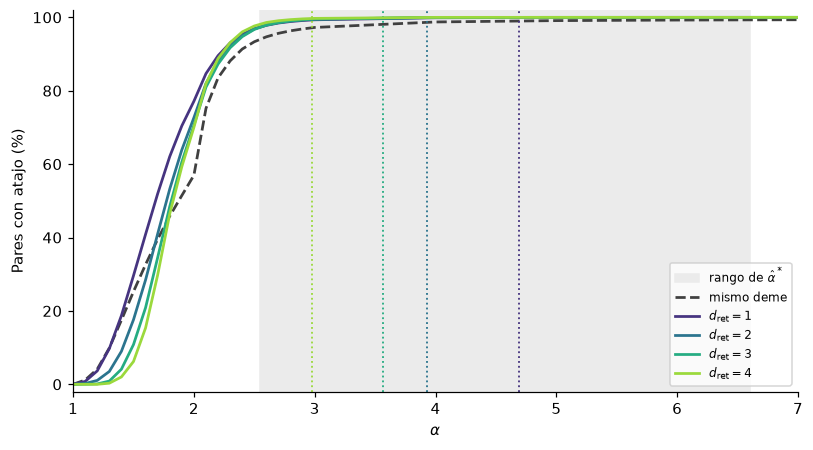

,alpha,Todos (%),Mismo deme (%),d_ret = 1 (%),d_ret = 2 (%),d_ret = 3 (%),d_ret = 4 (%)
0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
10,2.0,71.7,57.0,77.1,72.7,70.6,70.0
20,3.0,99.2,97.2,99.3,99.5,99.5,99.7
21,4.0,99.8,98.7,99.9,100.0,100.0,100.0


In [7]:
t = proporciones[proporciones.alpha <= 7]
alpha_por_distancia = por_distancia.set_index('d_ret')['alpha_estrella']
colores = plt.get_cmap('viridis')(np.linspace(0.15, 0.85, 4))

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.axvspan(diferenciacion['alpha*'].min(), diferenciacion['alpha*'].max(),
           color='0.92', zorder=0, label=r'rango de $\hat\alpha^*$')
ax.plot(t.alpha, t['Mismo deme (%)'], color='0.25', ls='--', lw=1.8, label='mismo deme')
for k, color in zip(range(1, 5), colores):
    ax.plot(t.alpha, t[f'd_ret = {k} (%)'], color=color, lw=1.8,
            label=rf'$d_{{\mathrm{{ret}}}}={k}$')
    ax.axvline(alpha_por_distancia[k], color=color, ls=':', lw=1.2)

ax.set(xlabel=r'$\alpha$', ylabel='Pares con atajo (%)', xlim=(1, 7), ylim=(-2, 102))
ax.legend(fontsize=8, loc='lower right')
fig.tight_layout()
guardar_figura(fig, 'aparicion_atajos')
plt.show()


display(proporciones[proporciones.alpha.isin([1, 2, 3, 4])].round(1))

## 3. Representaciones — Figuras 5.3 y 5.4

Para cada $\alpha\in\{1,2,3,4,5,6,7,8,9,10,12,15\}$ se construyeron MDS clásico y mapas de difusión usando $F_\alpha^{1/\alpha}$. Se evalúan mediante el error de Procrustes de los nueve centroides respecto de la retícula y $Q_{NN}(15)$. En $\alpha=1$ se recupera la distancia euclídea (salvo escala). Para la Figura 5.3 se muestran $\alpha=1,2,4,6,10$.

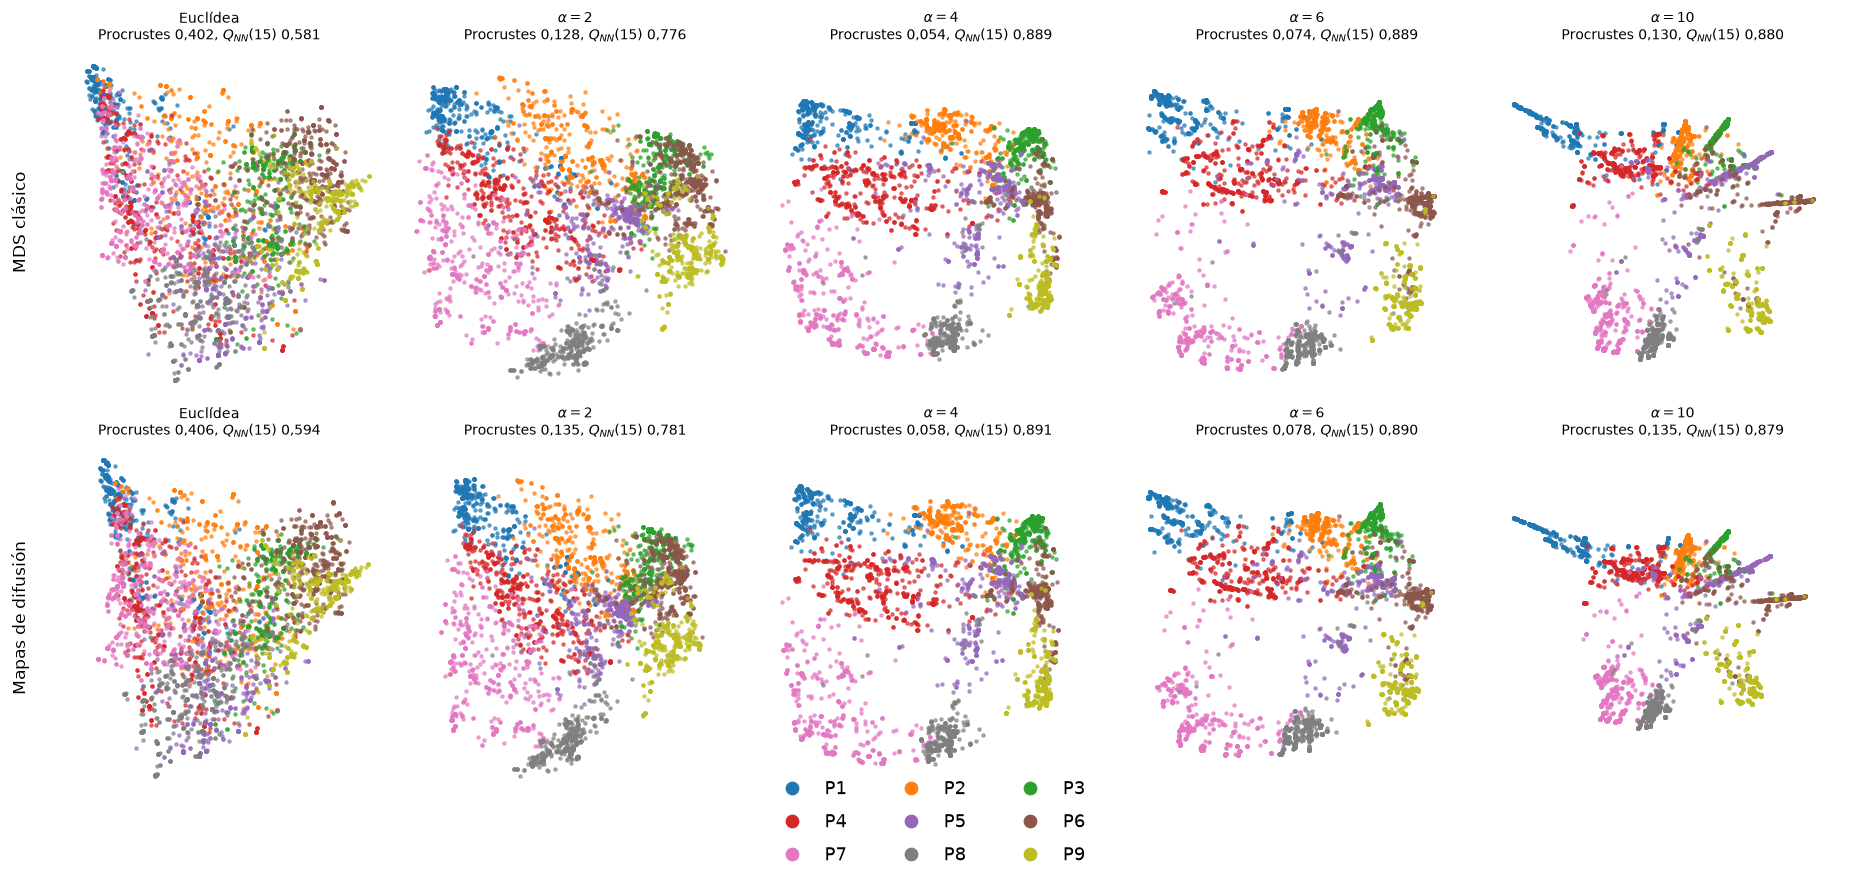

In [8]:
metricas_galeria = por_alpha[por_alpha.alpha.isin(ALPHAS_GALERIA)].copy()
from matplotlib.lines import Line2D

fig, axs = plt.subplots(2, 5, figsize=(17, 7.4))
for fila_ax, (metodo, _) in zip(axs, METODOS):
    for ax, alpha in zip(fila_ax, ALPHAS_GALERIA):
        Z = alinear_con_reticula(galeria[(metodo, alpha)])
        for a in range(9):
            ax.scatter(*Z[deme == a].T, s=4, alpha=.6, color=COLOR_DEME[DEMES[a]])
        m = metricas_galeria[(metricas_galeria['Método'] == metodo) &
                             (metricas_galeria.alpha == alpha)].iloc[0]
        nombre = 'Euclídea' if alpha == 1 else rf'$\alpha={alpha}$'
        ax.set_title(f'{nombre}\nProcrustes {m["Procrustes"]:.3f}, '
                     rf'$Q_{{NN}}(15)$ {m["Q_NN(15)"]:.3f}'.replace('.', ','), fontsize=9)
        ax.set_xticks([]); ax.set_yticks([])
        for lado in ax.spines.values():
            lado.set_visible(False)
        # 'anchor' fija el panel al borde superior de su celda, de modo que los títulos
        # quedan alineados aunque las nubes tengan proporciones distintas.
        ax.set_aspect('equal', anchor='N')
    fila_ax[0].set_ylabel(metodo, fontsize=11)

# Todos los paneles comparten límites, de manera que las escalas resulten comparables.
lims = [ax.get_xlim() + ax.get_ylim() for ax in axs.ravel()]
x0, x1 = min(l[0] for l in lims), max(l[1] for l in lims)
y0, y1 = min(l[2] for l in lims), max(l[3] for l in lims)
for ax in axs.ravel():
    ax.set(xlim=(x0, x1), ylim=(y0, y1))

# La leyenda reproduce la disposición de la retícula. Como matplotlib llena por columnas,
# se reordenan las entradas para que la primera fila sea P1, P2, P3.
orden = [0, 3, 6, 1, 4, 7, 2, 5, 8]
leyenda = [Line2D([], [], ls='', marker='o', ms=8, color=COLOR_DEME[DEMES[a]],
                  label=DEMES[a]) for a in orden]
fig.legend(handles=leyenda, loc='lower center', bbox_to_anchor=(.5, -.09),
           ncol=3, fontsize=12, frameon=False, columnspacing=2.5, labelspacing=.8)

fig.tight_layout(h_pad=3)
guardar_figura(fig, 'galeria_representaciones')
plt.show()

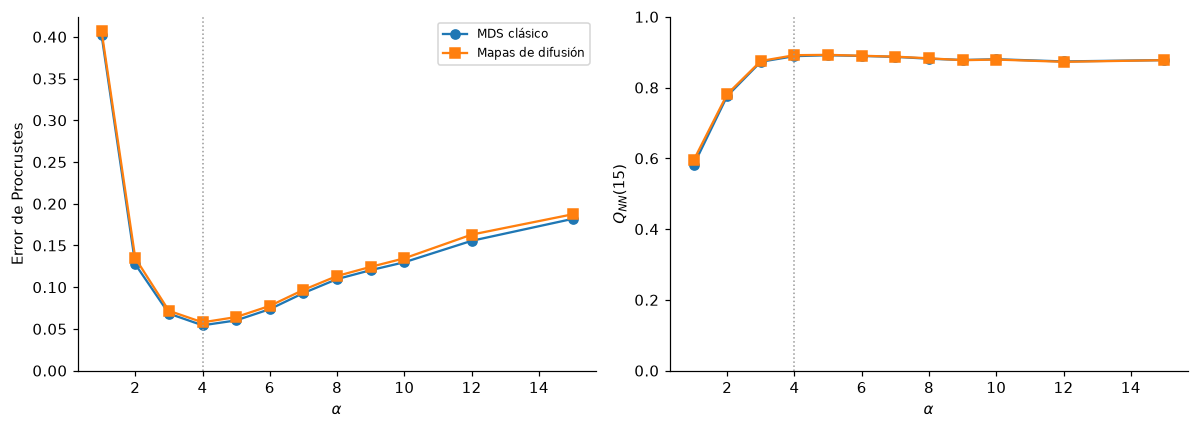

Procrustes                      Q_NN(15)                  
Método MDS clásico Mapas de difusión MDS clásico Mapas de difusión
alpha                                                             
1            0.402             0.406       0.581             0.594
2            0.128             0.135       0.776             0.781
3            0.068             0.072       0.873             0.875
4            0.054             0.058       0.889             0.891
5            0.060             0.064       0.891             0.892
6            0.074             0.078       0.889             0.890
7            0.093             0.097       0.887             0.887
8            0.110             0.113       0.882             0.883
9            0.120             0.124       0.878             0.877
10           0.130             0.135       0.880             0.879
12           0.156             0.163       0.874             0.873
15           0.182             0.187       0.878             0.877

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for metodo, marcador in [('MDS clásico', 'o'), ('Mapas de difusión', 's')]:
    t = por_alpha[por_alpha['Método'] == metodo]
    axs[0].plot(t.alpha, t['Procrustes'], marker=marcador, lw=1.5, label=metodo)
    axs[1].plot(t.alpha, t['Q_NN(15)'], marker=marcador, lw=1.5, label=metodo)
for ax in axs:
    ax.axvline(ALPHA_REP, color='0.6', ls=':', lw=1)
    ax.set_xlabel(r'$\alpha$')
axs[0].set(ylabel='Error de Procrustes', ylim=(0, None))
axs[1].set(ylabel=r'$Q_{NN}(15)$', ylim=(0, 1))
axs[0].legend(fontsize=8)
fig.tight_layout()
guardar_figura(fig, 'representaciones_por_alpha')
plt.show()

display(por_alpha.pivot(index='alpha', columns='Método').round(3))

## 4. Caminos P1–P8 — Figura 5.5 y Cuadro 5.3

Se sigue el camino mínimo entre un individuo fijo de P1 y otro de P8 para los exponentes de la grilla gruesa. Los puntos se dibujan en las posiciones de su deme con un pequeño desplazamiento aleatorio **solo visual**. La concordancia $Q_{\mathrm{ruta}}$ se calcula sobre 300 pares P1–P8 seleccionados con reemplazo, comparando sus secuencias de demes con las tres rutas mínimas de la retícula.

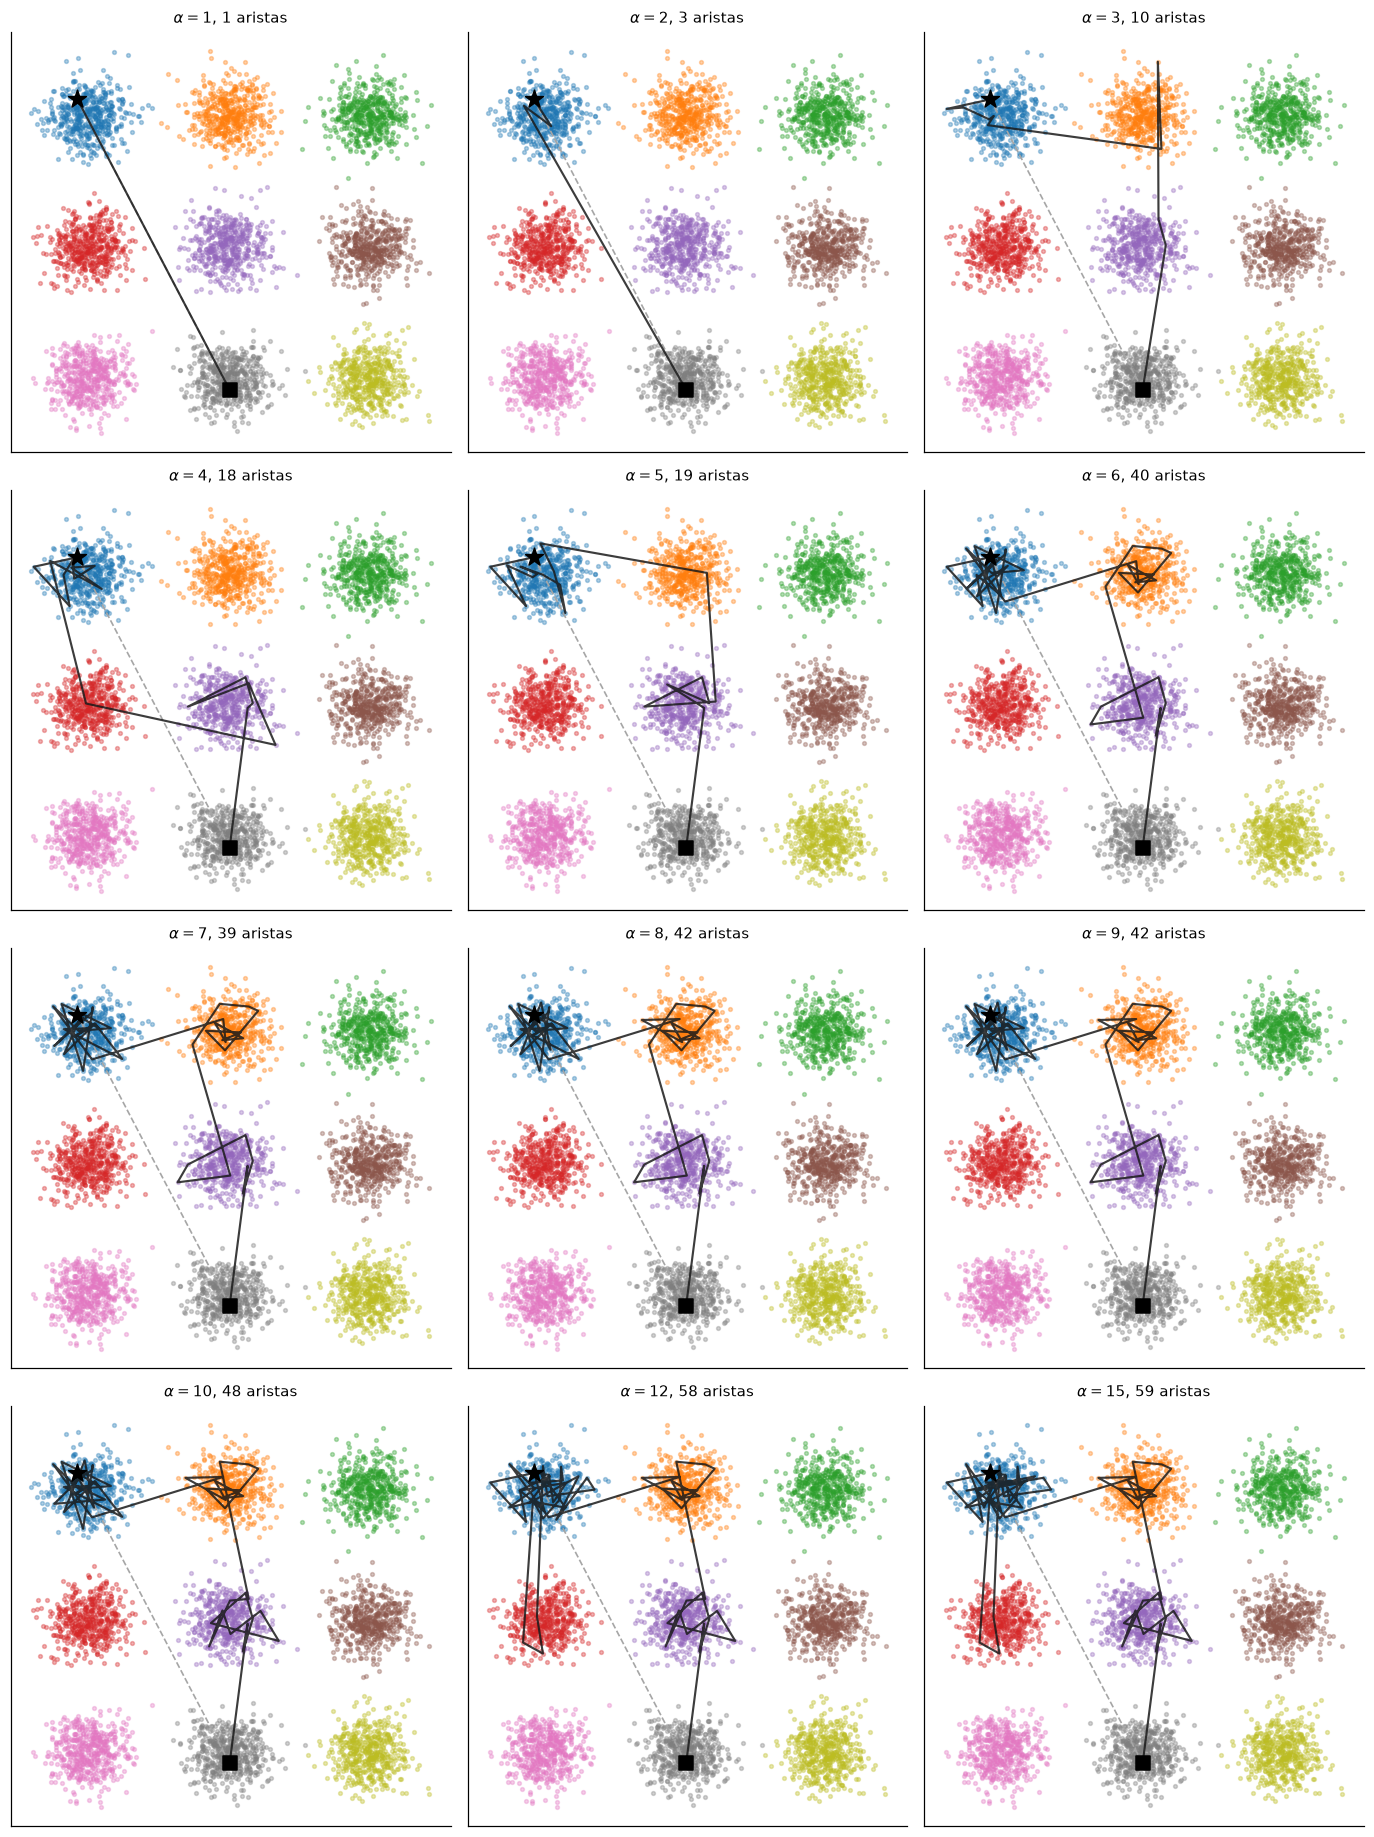

,alpha,aristas,demes
0,1,1,P1–P8
1,2,3,P1–P8
2,3,10,P1–P2–P5–P8
3,4,18,P1–P4–P5–P8
4,5,19,P1–P2–P5–P8
5,6,40,P1–P2–P5–P8
6,7,39,P1–P2–P5–P8
7,8,42,P1–P2–P5–P8
8,9,42,P1–P2–P5–P8
9,10,48,P1–P2–P5–P8


In [10]:
rng_figura = np.random.default_rng(SEED + 1)
posicion_dibujo = POSICION[deme][:, ::-1] * np.array([1, -1]) + rng_figura.normal(0, 0.14, (n, 2))

fig, axs = plt.subplots(4, 3, figsize=(12.6, 16.8))
for ax, alpha in zip(axs.ravel(), ALPHAS):
    camino = caminos_ilustrados[alpha]
    for a in range(9):
        m_a = deme == a
        ax.scatter(*posicion_dibujo[m_a].T, s=6, color=COLOR_DEME[DEMES[a]], alpha=0.35)
    ax.plot(*posicion_dibujo[[i0, j0]].T, color='0.65', ls='--', lw=1.1)
    ax.plot(*posicion_dibujo[camino].T, color='#1a1a1a', lw=1.4, alpha=0.85, zorder=3)
    ax.scatter(*posicion_dibujo[i0], marker='*', s=150, c='k', zorder=4)
    ax.scatter(*posicion_dibujo[j0], marker='s', s=75, c='k', zorder=4)
    ax.set_title(rf'$\alpha={alpha}$, {len(camino) - 1} aristas', fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
fig.tight_layout()
guardar_figura(fig, 'caminos_P1_P8')
plt.show()

display(recorridos.round(2))

In [11]:
# Cuadro 5.3 — porcentaje de caminos que siguen cada ruta mínima.
display(rutas[rutas.alpha.isin([2, 3, 4, 5, 6, 7, 8, 12])].round(1))

,alpha,P1–P2–P5–P8 (%),P1–P4–P5–P8 (%),P1–P4–P7–P8 (%),Q_ruta (%)
1,2,0.0,0.3,0.0,0.3
2,3,2.7,6.0,0.3,9.0
3,4,20.0,5.0,1.0,26.0
4,5,30.3,1.3,0.3,32.0
5,6,28.0,0.0,0.3,28.3
6,7,28.3,0.3,0.3,29.0
7,8,3.3,0.3,0.3,4.0
10,12,0.0,0.0,0.3,0.3


## 5. Robustez entre réplicas — Anexo C.1

Se repite la evaluación con **MDS clásico** sobre las primeras 30 réplicas disponibles, para $\alpha\in\{1,2,3,4,5,6,8,10\}$. Se muestran la media y el desvío estándar de Procrustes y $Q_{NN}(15)$ (Figura C.1). No se recalculan mapas de difusión, porque no forman parte de este análisis complementario.

Esta sección requiere los archivos `2D_stepstone_1.vcf` a `2D_stepstone_30.vcf`. Si faltan, se omite solamente el anexo; las figuras y cuadros de la primera réplica ya quedan generados. Por seguridad de memoria se procesa una réplica por vez.

Réplica 1/30 terminada
Réplica 2/30 terminada
Réplica 3/30 terminada
Réplica 4/30 terminada
Réplica 5/30 terminada
Réplica 6/30 terminada
Réplica 7/30 terminada
Réplica 8/30 terminada
Réplica 9/30 terminada
Réplica 10/30 terminada
Réplica 11/30 terminada
Réplica 12/30 terminada
Réplica 13/30 terminada
Réplica 14/30 terminada
Réplica 15/30 terminada
Réplica 16/30 terminada
Réplica 17/30 terminada
Réplica 18/30 terminada
Réplica 19/30 terminada
Réplica 20/30 terminada
Réplica 21/30 terminada
Réplica 22/30 terminada
Réplica 23/30 terminada
Réplica 24/30 terminada
Réplica 25/30 terminada
Réplica 26/30 terminada
Réplica 27/30 terminada
Réplica 28/30 terminada
Réplica 29/30 terminada
Réplica 30/30 terminada


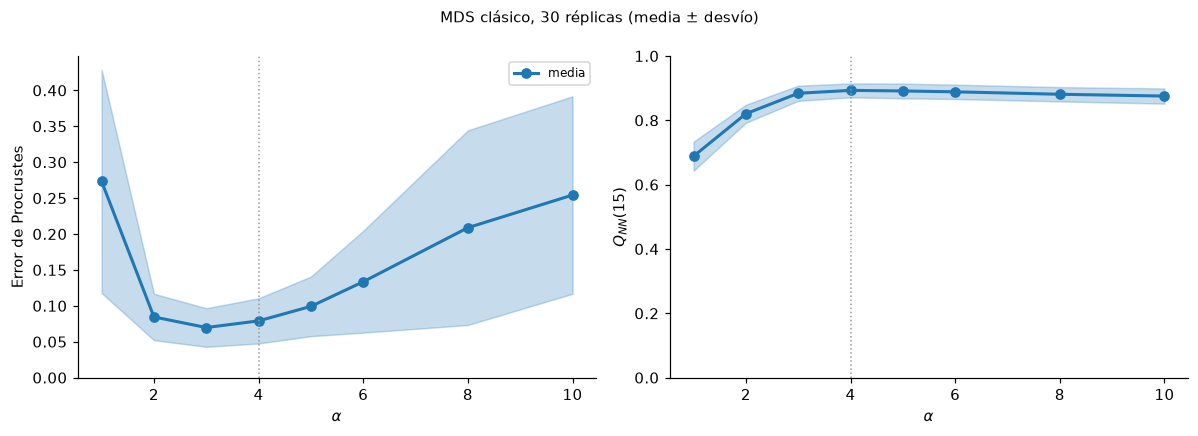

,proc_euc,proc_min,qnn_euc,qnn_min
mean,0.273,0.068,0.688,0.882
std,0.155,0.027,0.045,0.031


Exponente de menor Procrustes por réplica:


alpha_min
2     3
3    21
4     5
5     1
Name: count, dtype: int64

In [13]:
REPLICAS_ANEXO = range(1, 31)
ALPHAS_ANEXO = (1, 2, 3, 4, 5, 6, 8, 10)


def evaluar_replica(k):
    """Procrustes y Q_NN(15) de MDS clásico para una réplica adicional."""
    datos = leer_vcf(archivo_vcf(k))
    n_k, p_k = datos.shape
    if n_k != 4500:
        raise ValueError(f'Réplica {k}: cantidad inesperada de individuos: {n_k}')
    etiquetas = np.repeat(np.arange(9), 500)
    D_k = squareform(pdist(datos))
    escala_k = np.median(D_k[np.triu_indices(n_k, 1)])
    D_k /= escala_k
    salida = []
    for alpha in ALPHAS_ANEXO:
        if alpha == 1:
            distancias = D_k
        else:
            F_k = shortest_path(csr_matrix(D_k ** alpha), method='FW', directed=False)
            distancias = F_k ** (1 / alpha)
        Z = mds_clasico(distancias)
        salida.append({'replica': k, 'alpha': alpha,
                       'Procrustes': error_procrustes(Z, etiquetas),
                       'Q_NN(15)': q_nn(Z, 15, etiquetas)})
    return salida


faltantes = [k for k in REPLICAS_ANEXO if archivo_vcf(k) is None]
if faltantes:
    print(f'Anexo C.1 no ejecutado: faltan {len(faltantes)} VCF de las 30 réplicas.')
    print('Los resultados del cuerpo de la tesis ya se generaron.')
else:
    datos_replicas = []
    for k in REPLICAS_ANEXO:
        datos_replicas.extend(evaluar_replica(k))
        print(f'Réplica {k}/30 terminada')
    rep = guardar_tabla(pd.DataFrame(datos_replicas), 'robustez_replicas')

    fig, axs = plt.subplots(1, 2, figsize=(11, 4))
    for ax, col, etiqueta_y, ylim in [
        (axs[0], 'Procrustes', 'Error de Procrustes', (0, None)),
        (axs[1], 'Q_NN(15)', r'$Q_{NN}(15)$', (0, 1)),
    ]:
        piv = rep.pivot(index='alpha', columns='replica', values=col)
        media, desvio = piv.mean(axis=1), piv.std(axis=1)
        ax.fill_between(piv.index, media - desvio, media + desvio, alpha=.25, color='C0')
        ax.plot(piv.index, media, color='C0', lw=2, marker='o', label='media')
        ax.axvline(ALPHA_REP, color='0.6', ls=':', lw=1)
        ax.set(xlabel=r'$\alpha$', ylabel=etiqueta_y, ylim=ylim)
    axs[0].legend(fontsize=8)
    fig.suptitle('MDS clásico, 30 réplicas (media ± desvío)', fontsize=10)
    fig.tight_layout()
    guardar_figura(fig, 'robustez_replicas')
    plt.show()

    por_replica = []
    for k in REPLICAS_ANEXO:
        t = rep[rep.replica == k].set_index('alpha')
        alfa_min = t['Procrustes'].idxmin()
        por_replica.append({'proc_euc': t.loc[1, 'Procrustes'],
                            'proc_min': t.loc[alfa_min, 'Procrustes'],
                            'alpha_min': alfa_min,
                            'qnn_euc': t.loc[1, 'Q_NN(15)'],
                            'qnn_min': t.loc[alfa_min, 'Q_NN(15)']})
    por_replica = guardar_tabla(pd.DataFrame(por_replica), 'robustez_por_replica')
    display(por_replica[['proc_euc', 'proc_min', 'qnn_euc', 'qnn_min']]
            .agg(['mean', 'std']).round(3))
    print('Exponente de menor Procrustes por réplica:')
    display(por_replica.alpha_min.value_counts().sort_index())

---

**Correspondencia con la tesis.** La sección principal produce el **Cuadro 5.2**, las **Figuras 5.2 a 5.5** y el **Cuadro 5.3**. La última sección produce la **Figura C.1** y sus estadísticas. Los valores de referencia se calculan a partir de los datos; ninguna cifra de Resultados está fijada manualmente en el código. Se eliminaron las exploraciones adicionales (mapas de calor, esqueletos de aristas, clasificaciones alternativas de caminos y gráficos auxiliares) que no aparecen en la tesis.